This script is used to show the influence of the parameter k (number of neighbors to sample from) in velotest

In [1]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import seaborn as sns
import torch
import velotest
import yaml
from scipy import stats
from tqdm import tqdm
from velotest.hypothesis_testing import run_hypothesis_test_on
from velotest.neighbors import find_neighbors, find_neighbors_in_direction_of_velocity


In [2]:
def calculateBound(adata, k=None, neighbors=True, number_neighbors=200): 
    if neighbors is True:
        nn_indices_optimal = find_neighbors(torch.tensor(adata.layers['Ms']), k_neighbors=number_neighbors)

    mins = torch.tensor([-2.]*len(adata))
    maxs = torch.tensor([-2.]*len(adata))
    for i in tqdm(range(len(adata))):
        cos = torch.nn.CosineSimilarity(dim=1, eps=1e-6)
        if neighbors is True:
            expression_all = torch.tensor(adata.layers['Ms'][nn_indices_optimal[i]][:,adata.var.velocity_genes])
        else:
            expression_all = torch.tensor(adata.layers['Ms'][:,adata.var.velocity_genes])
        expression_cell = torch.tensor(adata.layers['Ms'][i,adata.var.velocity_genes]).unsqueeze(0)
        velocity = torch.tensor(adata.layers['velocity'][i,adata.var.velocity_genes]).unsqueeze(0)
        cosines = cos(expression_all - expression_cell, velocity)
        cosines = torch.cat([cosines[:i], cosines[i+1:]])
        if k is None:
            mins[i] = torch.min(cosines)
            maxs[i] = torch.max(cosines)
        else:
            mins[i] = torch.mean(torch.topk(cosines, largest=False, k=k).values)
            maxs[i] = torch.mean(torch.topk(cosines, largest=True, k=k).values)

    return maxs

def bestVelocityEmbedded(adata, basis, num=200):
    # Run test - tsne
    uncorrected_p_values, h0_rejected, debug_dict = run_hypothesis_test_on(adata, basis=basis, number_neighbors_to_sample_from=num, null_distribution="velocities-explicit", cosine_empty_neighborhood=None, correction="bonferroni", restrict_to_velocity_genes=True, exclusion_degree=10)
    statistics = debug_dict['statistics']

    # Calculate emmbeding test optimal statistic
    best_value = [statistics.get_max_value(offset=True)[1] for statistics in statistics if statistics is not None]

    return best_value

In [ ]:
# Get original values
datasets = {
        #"Pancreas_dynamical": "/mnt/volume/Johanna_Velotest/configs/pancreas_dynamic.yaml",
        #"Pancreas_stochastic": "/mnt/volume/Johanna_Velotest/configs/pancreas_stochastic.yaml",
        #"Dentate_gyrus": "/mnt/volume/Johanna_Velotest/configs/dentategyrus.yaml",
        #"Gastrulation_erythroid": "/mnt/volume/Johanna_Velotest/configs/gastrulation.yaml",
        #"Bone_marrow": "/mnt/volume/Johanna_Velotest/configs/bonemarrow.yaml",
        "PBMC": "/mnt/volume/Johanna_Velotest/configs/pbmc.yaml",
        #"Covid": "/mnt/volume/Johanna_Velotest/configs/covid.yaml",
        #"Retinal_development": "/mnt/volume/Johanna_Velotest/configs/retinal_development.yaml",
        #"Human_HSC": "/mnt/volume/Johanna_Velotest/configs/humanHSC.yaml",
        #"RPE_1": "/mnt/volume/Johanna_Velotest/configs/noEmbedding/intestinal_organoids.yaml",
        #"Hindbrain_mouse": "/mnt/volume/Johanna_Velotest/configs/noEmbedding/hindbrain.yaml",
        #"Oligodendrocyte_mouse": "/mnt/volume/Johanna_Velotest/configs/noEmbedding/oligodendrocyte.yaml",
        #"Bone_marrow_mouse": "/mnt/volume/Johanna_Velotest/configs/noEmbedding/mouse_bonemarrow.yaml",
        #"Cerebral_cortex_human": "/mnt/volume/Johanna_Velotest/configs/noEmbedding/human_cerebral.yaml",
        #"Hematopoiesis_mouse": "/mnt/volume/Johanna_Velotest/configs/noEmbedding/mouse_hema.yaml",
        #"Spermatogenisis": "/mnt/volume/Johanna_Velotest/configs/noEmbedding/spermatogenesis.yaml",
        #"Old_brain": "/mnt/volume/Johanna_Velotest/configs/noEmbedding/old_brain.yaml",
        #"Prefrontal_cortex": "/mnt/volume/Johanna_Velotest/configs/noEmbedding/pfc.yaml",
        #"Intestinal_organoids":"/mnt/volume/Johanna_Velotest/configs/noEmbedding/GSE128365.yaml",
        #"Zebra_NMP": "/mnt/volume/Johanna_Velotest/configs/noEmbedding/zebra_NMP.yaml"
    }

100%|██████████| 1267/1267 [00:35<00:00, 35.98it/s]


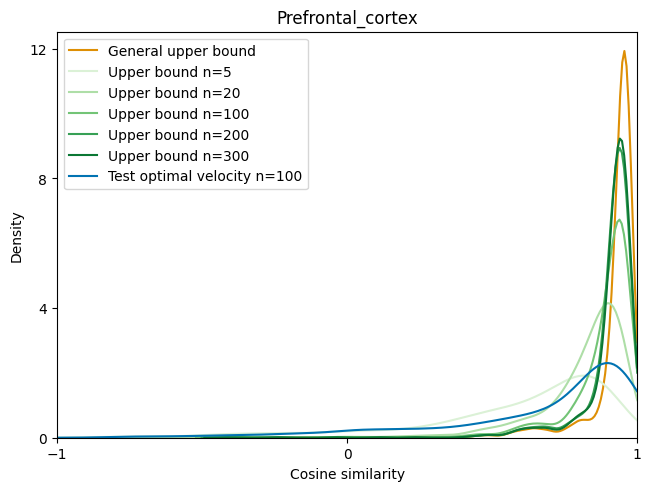

100%|██████████| 3831/3831 [01:42<00:00, 37.40it/s]


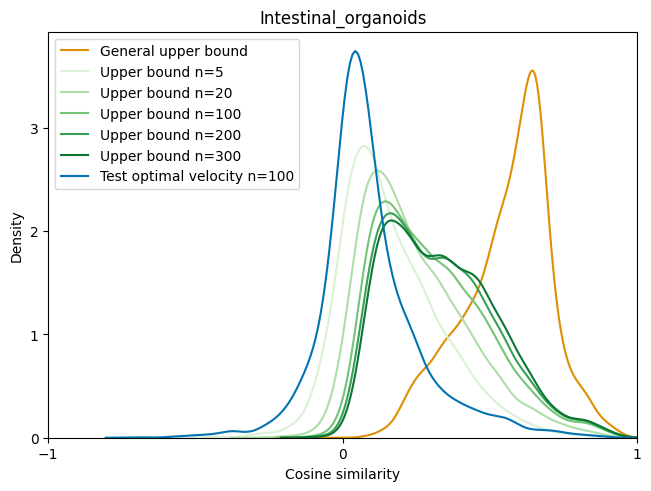

100%|██████████| 16035/16035 [09:15<00:00, 28.85it/s]


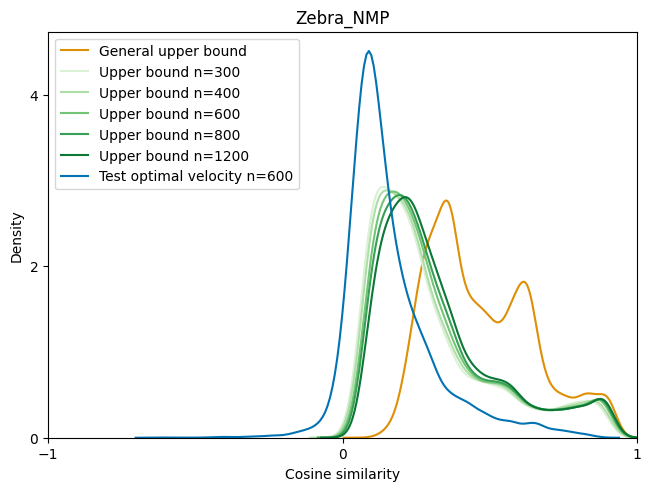

In [4]:
for name, path in datasets.items():
    with open(path, "r") as f:
            config = yaml.safe_load(f)
    # Load Dataset
    adata = sc.read(config["path"]) 
    original_neighbors = config['number_neighbors_to_sample_from']
    if original_neighbors == 100:
        neighbors = [5, 20, 100, 200, 300]
    elif original_neighbors == 200:
        neighbors = [20, 100, 200, 300, 400]
    elif original_neighbors == 300:
        neighbors = [100, 200, 300, 400, 600]
    elif original_neighbors == 400:
        neighbors = [200, 300, 400, 600, 800]
    elif original_neighbors == 600:
        neighbors = [300, 400, 600, 800, 1200]
    elif original_neighbors == 1600:
        neighbors = [800, 1200, 1600, 2000, 2500]
    elif original_neighbors == 2000:
        neighbors = [1200, 1600, 2000, 2500, 3000]
         
    _, ax = plt.subplots(constrained_layout=True)

    palette = sns.color_palette("Greens", len(neighbors))
    ax.set_prop_cycle(color=palette)

    # General upper bound
    upper_bound = adata.obsm['general_bound']
    sns.kdeplot(upper_bound, clip=(-1, 1), fill=False, color="#de8f05", 
                    label="General upper bound")

    # Upper bound with differnt neighbors
    for i, num in enumerate(neighbors):
        upper_bound = calculateBound(adata, neighbors=True, number_neighbors=num)
        sns.kdeplot(upper_bound, clip=(-1, 1), fill=False, color=palette[i], 
                    label=f"Upper bound n={num}")
    
    # Test optimal with original embedding
    bound = adata.uns['best_embedding']
    sns.kdeplot(bound, clip=(-1, 1), fill=False, color="#0173b2", 
                    label=f"Test optimal velocity n={original_neighbors}")

    ax.set_xlabel("Cosine similarity")
    ax.set_ylabel("Density")
    ax.legend()
    ax.set_title(name)
    ax.set_xlim(-1,1)
    ax.yaxis.set_major_locator(mpl.ticker.MaxNLocator(integer=True, nbins=4))
    ax.xaxis.set_major_locator(mpl.ticker.MaxNLocator(integer=True, nbins=3))
    
    plt.savefig(f"../results/bounds/{name}_different_k_bound.pdf", transparent=True, dpi=450)
    plt.show()
    plt.close()
    
    

100%|██████████| 36146/36146 [04:49<00:00, 124.70it/s]


Dropping all the genes which are not velocity genes. 384 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 36146/36146 [49:52<00:00, 12.08it/s]  


Exclusion radius in rad: 0.17453292519943295


100%|██████████| 36146/36146 [19:57<00:00, 30.19it/s]


...

Exclusion radius in rad: 0.17453292519943295


100%|██████████| 36146/36146 [28:55<00:00, 20.83it/s]


Dropping all the genes which are not velocity genes. 384 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 36146/36146 [2:31:16<00:00,  3.98it/s]  


Exclusion radius in rad: 0.17453292519943295


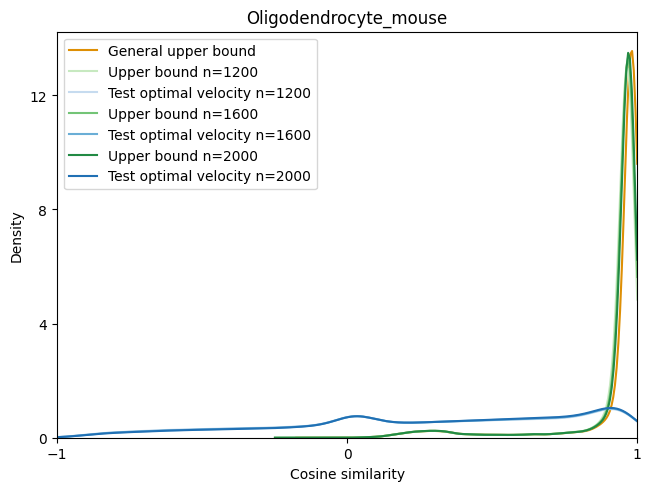

100%|██████████| 2600/2600 [01:09<00:00, 37.62it/s]


Dropping all the genes which are not velocity genes. 592 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 2600/2600 [00:09<00:00, 279.83it/s]


Exclusion radius in rad: 0.17453292519943295


100%|██████████| 2600/2600 [01:15<00:00, 34.36it/s]


...

Exclusion radius in rad: 0.17453292519943295


100%|██████████| 2600/2600 [01:13<00:00, 35.16it/s]


Dropping all the genes which are not velocity genes. 592 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 2600/2600 [00:27<00:00, 95.72it/s] 


Exclusion radius in rad: 0.17453292519943295


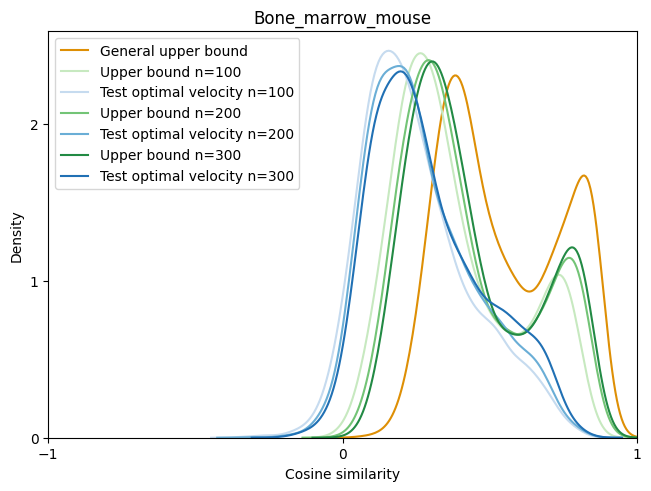

100%|██████████| 4693/4693 [01:56<00:00, 40.28it/s]


Dropping all the genes which are not velocity genes. 351 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 4693/4693 [00:15<00:00, 308.67it/s]


Exclusion radius in rad: 0.17453292519943295


100%|██████████| 4693/4693 [01:48<00:00, 43.19it/s]


...

Exclusion radius in rad: 0.17453292519943295


100%|██████████| 4693/4693 [00:29<00:00, 157.12it/s]


Dropping all the genes which are not velocity genes. 351 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 4693/4693 [00:50<00:00, 92.48it/s] 


Exclusion radius in rad: 0.17453292519943295


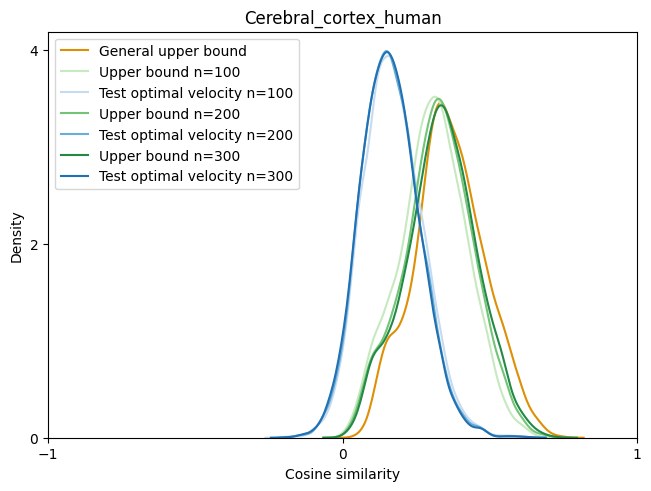

100%|██████████| 1772/1772 [00:46<00:00, 38.25it/s]


Dropping all the genes which are not velocity genes. 1218 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 1772/1772 [00:07<00:00, 242.28it/s]


Exclusion radius in rad: 0.17453292519943295


100%|██████████| 1772/1772 [00:47<00:00, 37.21it/s]


...

Exclusion radius in rad: 0.17453292519943295


100%|██████████| 1772/1772 [00:48<00:00, 36.83it/s]


Dropping all the genes which are not velocity genes. 1218 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 1772/1772 [00:18<00:00, 96.17it/s] 


Exclusion radius in rad: 0.17453292519943295


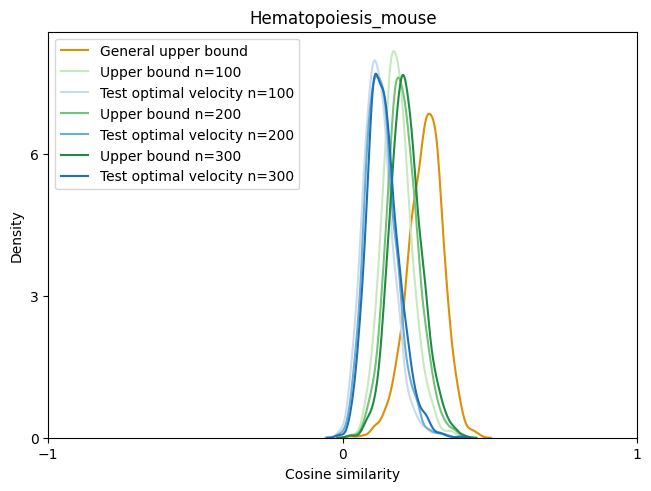

100%|██████████| 1829/1829 [00:02<00:00, 689.81it/s]


Dropping all the genes which are not velocity genes. 299 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 1829/1829 [00:10<00:00, 181.82it/s]


Exclusion radius in rad: 0.17453292519943295


100%|██████████| 1829/1829 [00:47<00:00, 38.90it/s]


...

Exclusion radius in rad: 0.17453292519943295


100%|██████████| 1829/1829 [00:46<00:00, 39.37it/s]


Dropping all the genes which are not velocity genes. 299 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 1829/1829 [00:20<00:00, 89.88it/s] 


Exclusion radius in rad: 0.17453292519943295


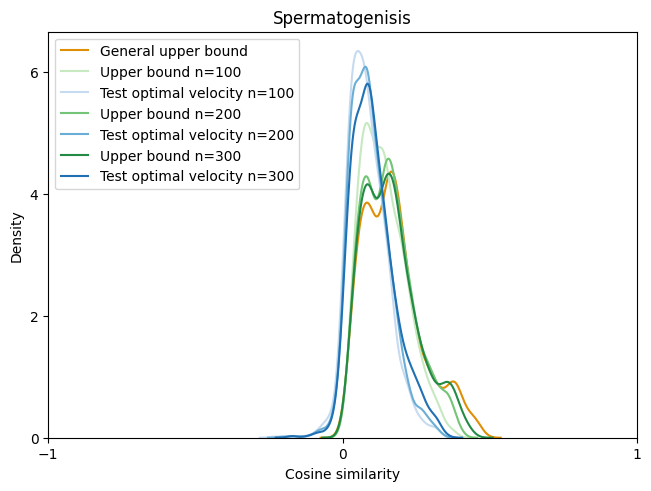

100%|██████████| 1823/1823 [00:46<00:00, 39.21it/s]


Dropping all the genes which are not velocity genes. 1302 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 1823/1823 [00:06<00:00, 266.72it/s]


Exclusion radius in rad: 0.17453292519943295


100%|██████████| 1823/1823 [00:28<00:00, 64.42it/s] 


...

Exclusion radius in rad: 0.17453292519943295


100%|██████████| 1823/1823 [00:49<00:00, 37.16it/s]


Dropping all the genes which are not velocity genes. 1302 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 1823/1823 [00:18<00:00, 96.11it/s] 


Exclusion radius in rad: 0.17453292519943295


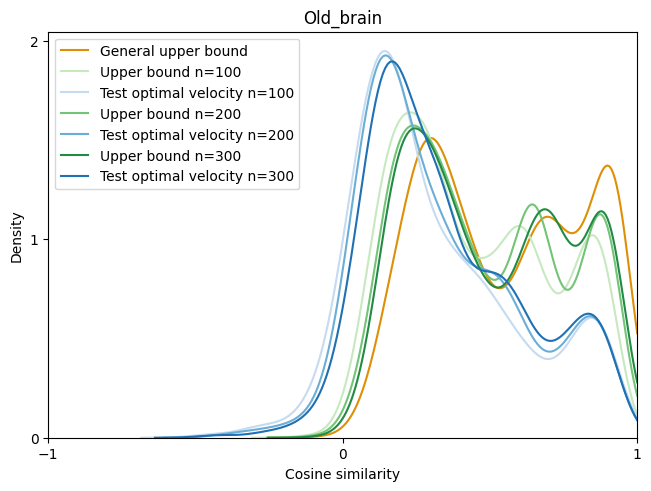

100%|██████████| 1267/1267 [00:33<00:00, 38.14it/s]


Dropping all the genes which are not velocity genes. 1232 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 1267/1267 [00:05<00:00, 237.41it/s]


Exclusion radius in rad: 0.17453292519943295


100%|██████████| 1267/1267 [00:32<00:00, 38.79it/s]


...

Exclusion radius in rad: 0.17453292519943295


100%|██████████| 1267/1267 [00:33<00:00, 38.17it/s]


Dropping all the genes which are not velocity genes. 1232 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 1267/1267 [00:13<00:00, 93.91it/s] 


Exclusion radius in rad: 0.17453292519943295


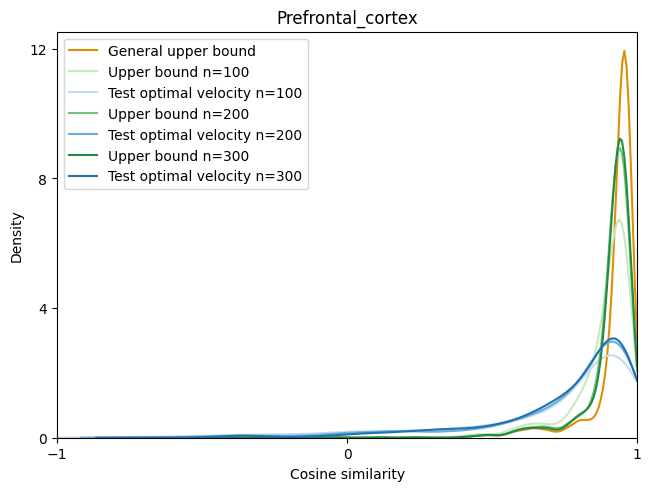

100%|██████████| 3831/3831 [00:03<00:00, 1020.37it/s]


Dropping all the genes which are not velocity genes. 156 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 3831/3831 [00:13<00:00, 283.27it/s]


Exclusion radius in rad: 0.17453292519943295


100%|██████████| 3831/3831 [00:05<00:00, 747.02it/s]


...

Exclusion radius in rad: 0.17453292519943295


100%|██████████| 3831/3831 [01:39<00:00, 38.43it/s]


Dropping all the genes which are not velocity genes. 156 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 3831/3831 [00:38<00:00, 98.40it/s] 


Exclusion radius in rad: 0.17453292519943295


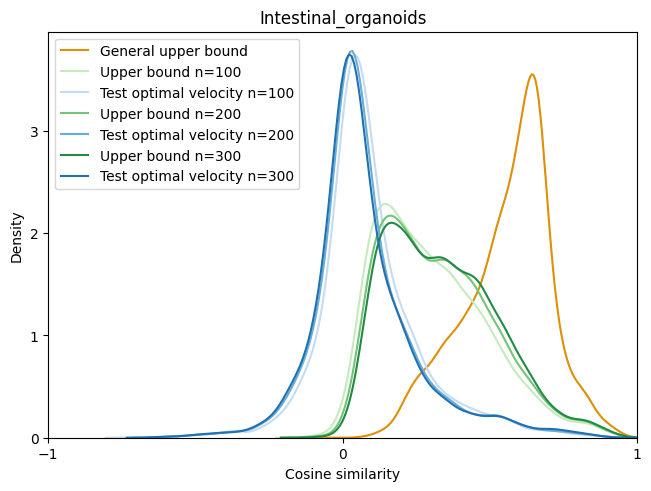

100%|██████████| 16035/16035 [04:48<00:00, 55.67it/s] 


Dropping all the genes which are not velocity genes. 897 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 16035/16035 [04:32<00:00, 58.90it/s] 


Exclusion radius in rad: 0.17453292519943295


100%|██████████| 16035/16035 [06:11<00:00, 43.14it/s] 


...

Exclusion radius in rad: 0.17453292519943295


100%|██████████| 16035/16035 [06:28<00:00, 41.31it/s] 


Dropping all the genes which are not velocity genes. 897 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 16035/16035 [10:52<00:00, 24.58it/s]


Exclusion radius in rad: 0.17453292519943295


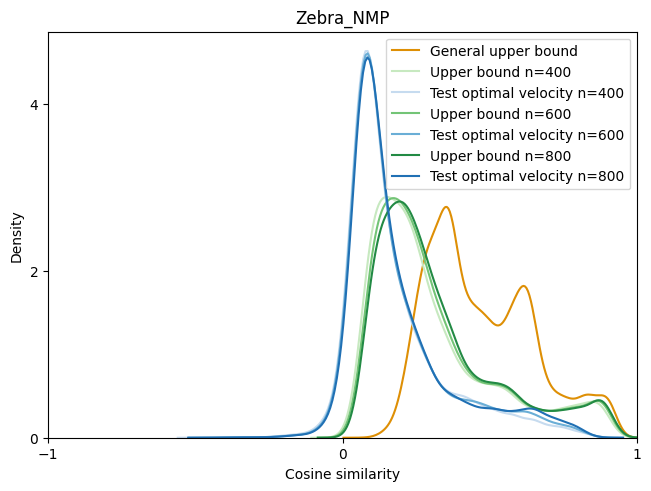

        Oligodendrocyte_mouse  Bone_marrow_mouse  Cerebral_cortex_human  \
n_1200               0.628666                NaN                    NaN   
n_1600               0.619837                NaN                    NaN   
n_2000               0.610998                NaN                    NaN   
n_100                     NaN           0.133830               0.137131   
n_200                     NaN           0.149393               0.161789   
n_300                     NaN           0.147116               0.172610   
n_400                     NaN                NaN                    NaN   
n_600                     NaN                NaN                    NaN   
n_800                     NaN                NaN                    NaN   

        Hematopoiesis_mouse  Spermatogenisis  Old_brain  Prefrontal_cortex  \
n_1200                  NaN              NaN        NaN                NaN   
n_1600                  NaN              NaN        NaN                NaN   
n_2000         

In [4]:
results = {}

for name, path in datasets.items():
    with open(path, "r") as f:
            config = yaml.safe_load(f)
    # Load Dataset
    adata = sc.read(config["path"]) 
    original_neighbors = config['number_neighbors_to_sample_from']
    if original_neighbors == 100 or original_neighbors == 200:
        neighbors = [100, 200, 300]
    elif original_neighbors == 300:
        neighbors = [200, 300, 400]
    elif original_neighbors == 400:
        neighbors = [300, 400, 600]
    elif original_neighbors == 600:
        neighbors = [400, 600, 800]
    elif original_neighbors == 1600:
        neighbors = [1200, 1600, 2000]
    elif original_neighbors == 2000:
        neighbors = [1600, 2000, 2500]

    _, ax = plt.subplots(constrained_layout=True)

    palette1 = sns.color_palette("Greens", len(neighbors))
    ax.set_prop_cycle(color=palette1)

    palette2 = sns.color_palette("Blues", len(neighbors))
    ax.set_prop_cycle(color=palette2)

    # General upper bound
    general = adata.obsm['general_bound']
    sns.kdeplot(general, clip=(-1, 1), fill=False, color="#de8f05", 
                    label="General upper bound")

    distances = {}
    # Upper bound with differnt neighbors
    for i, num in enumerate(neighbors):
        upper_bound = calculateBound(adata, neighbors=True, number_neighbors=num)
        sns.kdeplot(upper_bound, clip=(-1, 1), fill=False, color=palette1[i], 
                    label=f"Upper bound n={num}")
    
        # Test optimal with original embedding
        bound = bestVelocityEmbedded(adata, "umap", num)
        sns.kdeplot(bound, clip=(-1, 1), fill=False, color=palette2[i], 
                        label=f"Test optimal velocity n={num}")

        distances[f"n_{num}"] = stats.wasserstein_distance(upper_bound, bound)

    results[name] = distances
    ax.set_xlabel("Cosine similarity")
    ax.set_ylabel("Density")
    ax.legend()
    ax.set_title(name)
    ax.set_xlim(-1,1)
    ax.yaxis.set_major_locator(mpl.ticker.MaxNLocator(integer=True, nbins=4))
    ax.xaxis.set_major_locator(mpl.ticker.MaxNLocator(integer=True, nbins=3))
    
    plt.savefig(f"../results/bounds/{name}_different_k.pdf", transparent=True, dpi=450)
    plt.show()
    plt.close()

df = pd.DataFrame(results)
print(df)